# Gaia Variable Star Classification Modeling

## Imports and Configuration

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import MissingIndicator, SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from sklearn.dummy import DummyClassifier
from sklearn.metrics import precision_recall_fscore_support

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

for path in (root / "src", root):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

from gaia_variable_stars.config import (
    CLASSES, CV_FILE, FEATURE_FILE, FIGURES_ROOT, FOLDS,
    MIN_POINTS, MODEL_FILE, MODELS_ROOT, PRED_FILE,
    RANK_FILE, SEED, SOURCE_FILE,
)

FE_FEATURE_FILE = FEATURE_FILE.with_name("gaia_features_fe.csv")
FE_VALIDATION_FILE = FEATURE_FILE.with_name("gaia_period_validation_fe.csv")
FE_ORACLE_FILE = FEATURE_FILE.with_name("gaia_features_fe_oracle.csv")

EXTRA_ROOT = MODELS_ROOT / "gaia_classification"
PLOT_ROOT = FIGURES_ROOT / "gaia_classification"

for path in (MODELS_ROOT, EXTRA_ROOT, PLOT_ROOT):
    path.mkdir(parents=True, exist_ok=True)

REPEATS = 5
BOOTSTRAPS = 1500
PERM_REPEATS = 5
MIN_CELL = 10

## Features

In [2]:
GROUPS = {
    "period": [
        "log_period", "power", "half_power", "double_power",
        "half_power_ratio", "double_power_ratio", "fourier_amp", "fourier_ratio",
    ],
    "shape": [
        "magnitude_std", "magnitude_skew", "magnitude_kurt",
        "magnitude_mad", "amplitude", "beyond_1sigma_fraction",
    ],
    "timescale": [
        "von_neumann_eta", "stetson_j", "sf_short",
        "sf_long", "sf_ratio", "max_visit_slope",
    ],
    "color": ["bp_rp_color"],
    "brightness_noise": ["magnitude_mean", "median_error", "amplitude_ratio"],
    "sampling": [
        "n_epochs", "time_span", "median_gap", "short_gap_fraction",
        "n_visits", "epochs_per_visit", "median_visit_gap", "visit_gap_cv",
    ],
}

MAIN_GROUPS = [name for name in GROUPS if name != "sampling"]

def columns(names):
    return [col for name in names for col in GROUPS[name]]

BASE_FEATURES = columns(MAIN_GROUPS)
ALL_FEATURES = columns(GROUPS)

In [3]:
B_STATS = ["magnitude_std", "magnitude_mad", "magnitude_skew", "magnitude_kurt", "amplitude"]

FOURIER_EXTRA = ["R31_naive", "phi21_naive", "phi31_naive"]

C_TIME = B_STATS + GROUPS["period"] + FOURIER_EXTRA

In [4]:
FEATURE_SETS = {
    "full": BASE_FEATURES,
    "oracle": BASE_FEATURES,
    "period_free": columns([name for name in MAIN_GROUPS if name != "period"]),
    "color_amp": ["bp_rp_color", "amplitude"],
    "A_metadata": ["bp_rp_color", "magnitude_mean"],
    "B_stats": B_STATS,
    "C_timedomain": C_TIME,
    "D_full": C_TIME + ["bp_rp_color"],
}

for col in ["magnitude_std", "amplitude", "fourier_amp"]:
    FEATURE_SETS[f"drop_{col}"] = [c for c in BASE_FEATURES if c != col]

## Data

In [5]:
sources = pd.read_csv(SOURCE_FILE)
features = pd.read_csv(FE_FEATURE_FILE)
validation = pd.read_csv(FE_VALIDATION_FILE)
oracle = pd.read_csv(FE_ORACLE_FILE)

source_cols = [
    "source_id", "class_name", "ra", "dec", "ecl_lat",
    "bp_rp_color", "g_mean_magnitude", "gaia_period", "gaia_period_origin",
]

period_cols = [
    "period_eligible", "phase_coherent_recovery",
    "relative_period_accurate", "half_period_alias",
    "double_period_alias", "n_cycles", "sky_cell",
]

feature_cols = columns(["period", "shape", "timescale", "brightness_noise"]) + FOURIER_EXTRA

stars = (
    sources[source_cols]
    .merge(
        validation[["source_id", *period_cols, *GROUPS["sampling"]]],
        on="source_id", how="left", validate="one_to_one"
    )
    .merge(
        features[["source_id", *feature_cols]],
        on="source_id", how="left", validate="one_to_one"
    )
    .sort_values("source_id")
    .reset_index(drop=True)
)

if len(stars) != 2000 or stars["sky_cell"].isna().any():
    raise ValueError("Expected 2,000 stars with period-validation and sky-cell data.")

dropped = len(stars) - len(features)
stars = stars.loc[stars["source_id"].isin(features["source_id"])].reset_index(drop=True)
assert len(stars) == len(features)

numeric = list(dict.fromkeys([
    *ALL_FEATURES, *FOURIER_EXTRA, "ra", "dec", "ecl_lat", "g_mean_magnitude",
    "gaia_period", "n_cycles",
]))

stars[numeric] = stars[numeric].apply(pd.to_numeric, errors="coerce")
stars[numeric] = stars[numeric].replace([np.inf, -np.inf], np.nan)

stars["eligible"] = stars["period_eligible"].fillna(False).astype(bool)
stars["period_recovered"] = (
    stars["eligible"] & stars["phase_coherent_recovery"].fillna(False).astype(bool)
)

stars["period_status"] = np.select(
    [~stars["eligible"], stars["period_recovered"]],
    ["ineligible", "recovered"],
    default="mismatched",
)

stars["abs_ecl_lat"] = stars["ecl_lat"].abs()

oracle_stars = stars.copy()
reference = oracle.set_index("source_id").reindex(
    stars.loc[stars["eligible"], "source_id"]
)

if reference["log_period"].isna().any():
    raise ValueError("Oracle periods are missing for eligible stars.")

oracle_stars.loc[stars["eligible"], GROUPS["period"]] = (
    reference[GROUPS["period"]].to_numpy()
)

print("Total stars:", len(stars))
print("Feature rows:", len(features))
print("Rows without extracted features:", dropped)

Total stars: 1978
Feature rows: 1978
Rows without extracted features: 22


In [6]:
display(
    pd.crosstab(stars["class_name"], stars["period_status"])
    .reindex(
        index=CLASSES,
        columns=["recovered", "mismatched", "ineligible"],
        fill_value=0,
    )
)

period_status,recovered,mismatched,ineligible
class_name,,,
RR Lyrae,392,86,0
Cepheid,495,5,0
Eclipsing Binary,12,488,0
Long-Period Variable,269,132,99


## Cross-Validation

In [7]:
y = stars["class_name"].to_numpy()
sky = stars["sky_cell"].to_numpy()

splits = []
folds = np.zeros((REPEATS, len(stars)), dtype=np.uint8)

for repeat in range(REPEATS):
    cv = StratifiedGroupKFold(
        n_splits=FOLDS, shuffle=True, random_state=SEED + 101 * repeat
    )

    for fold, (train, test) in enumerate(cv.split(stars, y, sky), start=1):
        if len(np.unique(y[train])) != len(CLASSES):
            raise ValueError(f"Training class missing in repeat {repeat + 1}, fold {fold}.")

        folds[repeat, test] = fold
        splits.append((repeat, fold, train, test))

if (folds == 0).any():
    raise ValueError("Some stars have no out-of-fold prediction assignment.")

print("Sky cells:", stars["sky_cell"].nunique())
print("Folds:", FOLDS)
print("Repeats:", REPEATS)

Sky cells: 167
Folds: 5
Repeats: 5


In [8]:
fold_counts = pd.crosstab(stars["class_name"], folds[0]).reindex(CLASSES)
fold_counts.columns = [f"test_fold_{c}" for c in fold_counts.columns]
fold_counts.insert(0, "total", fold_counts.sum(axis=1))
fold_counts.to_csv(EXTRA_ROOT / "fold_counts.csv")
display(fold_counts)

,total,test_fold_1,test_fold_2,test_fold_3,test_fold_4,test_fold_5
class_name,,,,,,
RR Lyrae,478,95,95,96,96,96
Cepheid,500,118,95,95,96,96
Eclipsing Binary,500,80,126,127,87,80
Long-Period Variable,500,156,103,76,82,83


## Models

In [9]:
def make_model(name, variant):
    if name == "Dummy":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("model", DummyClassifier(strategy="stratified", random_state=SEED)),
        ])

    if name == "LR":
        return Pipeline([
            ("imputer", SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)),
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(max_iter=5000, random_state=SEED)),
        ])

    if name == "RF":
        return Pipeline([
            ("imputer", SimpleImputer(
                strategy="median", add_indicator=True, keep_empty_features=True
            )),
            ("model", RandomForestClassifier(
                n_estimators=250, min_samples_leaf=2,
                max_features="sqrt", random_state=SEED, n_jobs=-1
            )),
        ])

    model = HistGradientBoostingClassifier(
        max_iter=250, learning_rate=0.05, min_samples_leaf=15,
        l2_regularization=1.0, random_state=SEED,
    )
    return Pipeline([
        ("flags", FeatureUnion([
            ("values", FunctionTransformer()),
            ("missing", MissingIndicator(features="all", sparse=False)),
        ])),
        ("model", model),
    ])

In [10]:
importance_rows = []
family_rows = []

def predict_oof(name, variant):
    cols = FEATURE_SETS[variant]
    data = oracle_stars if variant == "oracle" else stars
    result = np.full((REPEATS, len(stars)), None, dtype=object)

    for repeat, fold, train, test in splits:
        model = make_model(name, variant)
        model.fit(data.iloc[train][cols], y[train])
        result[repeat, test] = model.predict(data.iloc[test][cols])

        if name == "HGB" and variant == "full" and repeat == 0:
            score = permutation_importance(
                model, data.iloc[test][cols], y[test],
                scoring=lambda fit, x, truth: f1_score(
                    truth, fit.predict(x), labels=CLASSES,
                    average="macro", zero_division=0
                ),
                n_repeats=PERM_REPEATS, random_state=SEED + fold, n_jobs=1,
            )
            for col, decrease in zip(cols, score.importances_mean):
                importance_rows.append({
                    "fold": fold, "feature": col,
                    "macro_f1_drop": float(decrease),
                })

            x_test = data.iloc[test][cols]
            rng = np.random.default_rng(SEED + fold)
            base = f1_score(y[test], model.predict(x_test), labels=CLASSES,
                            average="macro", zero_division=0)
            for family, members in GROUPS.items():
                present = [c for c in members if c in cols]
                if not present:
                    continue
                drops = []
                for _ in range(PERM_REPEATS):
                    shuffled = x_test.copy()
                    shuffled[present] = x_test[present].to_numpy()[rng.permutation(len(x_test))]
                    drops.append(base - f1_score(
                        y[test], model.predict(shuffled), labels=CLASSES,
                        average="macro", zero_division=0))
                family_rows.append({"fold": fold, "family": family,
                                    "macro_f1_drop": float(np.mean(drops))})

    return result

## RF and HGB Predictions

In [11]:
MAIN = ["full", "oracle", "period_free", "color_amp"]
ABLATION = ["A_metadata", "B_stats", "C_timedomain", "D_full"]
REDUNDANCY = ["drop_magnitude_std", "drop_amplitude", "drop_fourier_amp"]

predictions = {}

for name in ["RF", "HGB"]:
    for variant in MAIN + ABLATION + REDUNDANCY:
        predictions[(name, variant)] = predict_oof(name, variant)
        print(f"{name}: {variant}")

for name in ["Dummy", "LR"]:
    predictions[(name, "full")] = predict_oof(name, "full")
    print(f"{name}: full")

RF: full
RF: oracle
RF: period_free
RF: color_amp
RF: A_metadata
RF: B_stats
RF: C_timedomain
RF: D_full
RF: drop_magnitude_std
RF: drop_amplitude
RF: drop_fourier_amp
HGB: full
HGB: oracle
HGB: period_free
HGB: color_amp
HGB: A_metadata
HGB: B_stats
HGB: C_timedomain
HGB: D_full
HGB: drop_magnitude_std
HGB: drop_amplitude
HGB: drop_fourier_amp
Dummy: full
LR: full


## Out-of-Fold Predictions

In [16]:
oof = pd.concat([
    stars[["source_id", "class_name", "sky_cell", "period_status"]]
    .assign(repeat=repeat + 1, fold=folds[repeat])
    for repeat in range(REPEATS)
], ignore_index=True)

for (name, variant), values in predictions.items():
    pred_col = f"pred_{name}_{variant}"
    correct_col = f"correct_{name}_{variant}"

    oof[pred_col] = values.ravel()
    oof[correct_col] = oof[pred_col].eq(oof["class_name"])

if len(oof) != len(stars) * REPEATS or oof.filter(like="pred_").isna().any().any():
    raise ValueError("Out-of-fold predictions are incomplete.")

oof.to_csv(PRED_FILE, index=False)
oof[["source_id", "class_name", "repeat", "fold"]].to_csv(EXTRA_ROOT / "splits.csv", index=False)

print("Unique Stars:", oof["source_id"].nunique())
print("Out-of-fold predictions per model:", len(oof))
print("Feature Sets:", len(predictions))

Unique Stars: 1978
Out-of-fold predictions per model: 9890
Feature Sets: 24


## Model Scores

In [18]:
score_rows = []
class_rows = []

for (name, variant) in predictions:
    col = f"pred_{name}_{variant}"

    for repeat, part in oof.groupby("repeat"):
        truth = part["class_name"]
        predicted = part[col]

        score_rows.append({
            "model": name,
            "feature_set": variant,
            "repeat": repeat,
            "n": len(part),
            "accuracy": accuracy_score(truth, predicted),
            "balanced_accuracy": balanced_accuracy_score(truth, predicted),
            "macro_f1": f1_score(
                truth, predicted, labels=CLASSES,
                average="macro", zero_division=0
            ),
        })

        for class_name in CLASSES:
            group = part.loc[truth.eq(class_name)]
            class_rows.append({
                "model": name, "feature_set": variant,
                "repeat": repeat, "class_name": class_name,
                "n": len(group), "recall": group[col].eq(class_name).mean(),
            })

cv_scores = pd.DataFrame(score_rows)
class_scores = pd.DataFrame(class_rows)

rank_rows = []

for (name, variant), part in cv_scores.groupby(["model", "feature_set"]):
    row = {"model": name, "feature_set": variant, "repeats": REPEATS}

    for metric in ["accuracy", "balanced_accuracy", "macro_f1"]:
        values = part[metric].to_numpy()
        row[f"{metric}_mean"] = values.mean()
        row[f"{metric}_min"] = values.min()
        row[f"{metric}_max"] = values.max()

    rank_rows.append(row)

cv_ranking = pd.DataFrame(rank_rows).sort_values(["feature_set", "model"])

cv_class = class_scores.groupby(
    ["model", "feature_set", "class_name"], as_index=False
).agg(
    recall_mean=("recall", "mean"),
    recall_min=("recall", "min"),
    recall_max=("recall", "max"),
)

cv_scores.to_csv(CV_FILE, index=False)
cv_ranking.to_csv(RANK_FILE, index=False)
cv_class.to_csv(EXTRA_ROOT / "classes.csv", index=False)

selected = cv_ranking.loc[cv_ranking["feature_set"].isin(MAIN)]

display(
    selected.pivot(
        index="feature_set", columns="model",
        values=[
            "accuracy_mean", "accuracy_min", "accuracy_max",
            "macro_f1_mean", "macro_f1_min", "macro_f1_max",
        ],
    ).round(4)
)

accuracy_mean                         accuracy_min          \
model               Dummy     HGB      LR      RF        Dummy     HGB   
feature_set                                                              
color_amp             NaN  0.5436     NaN  0.5667          NaN  0.5394   
full               0.2427  0.9733  0.9368  0.9722       0.2346  0.9722   
oracle                NaN  0.9824     NaN  0.9810          NaN  0.9808   
period_free           NaN  0.9378     NaN  0.9305          NaN  0.9353   

                            accuracy_max          ... macro_f1_mean          \
model            LR      RF        Dummy     HGB  ...            LR      RF   
feature_set                                       ...                         
color_amp       NaN  0.5632          NaN  0.5490  ...           NaN  0.5611   
full         0.9358  0.9712       0.2487  0.9747  ...        0.9365  0.9720   
oracle          NaN  0.9793          NaN  0.9838  ...           NaN  0.9809   
period_free     NaN  0.9262          NaN  0.9398  ...           NaN  0.9304   

            macro_f1_min                         macro_f1_max                  \
model              Dummy     HGB      LR      RF        Dummy     HGB      LR   
feature_set                                                                     
color_amp            NaN  0.5355     NaN  0.5581          NaN  0.5465     NaN   
full              0.2342  0.9720  0.9354  0.9710       0.2479  0.9746  0.9394   
oracle               NaN  0.9807     NaN  0.9791          NaN  0.9837     NaN   
period_free          NaN  0.9351     NaN  0.9259          NaN  0.9396     NaN   

                     
model            RF  
feature_set          
color_amp    0.5643  
full         0.9736  
oracle       0.9822  
period_free  0.9341  

[4 rows x 24 columns]

## Metrics with 95% CI

In [19]:
K = len(CLASSES)
CLASS_INDEX = {name: i for i, name in enumerate(CLASSES)}
truth_all = stars["class_name"].map(CLASS_INDEX).to_numpy()


def metrics_from_counts(cm):
    tp = np.diag(cm).astype(float)
    support, predicted = cm.sum(axis=1), cm.sum(axis=0)
    with np.errstate(divide="ignore", invalid="ignore"):
        recall = np.where(support > 0, tp / support, 0.0)
        precision = np.where(predicted > 0, tp / predicted, 0.0)
        f1 = np.where(precision + recall > 0, 2 * precision * recall / (precision + recall), 0.0)
    return np.array([tp.sum() / cm.sum(), recall.mean(), f1.mean()])


def predictions_matrix(name, variant):
    col = f"pred_{name}_{variant}"
    return np.stack([part[col].map(CLASS_INDEX).to_numpy() for _, part in oof.groupby("repeat")])


def bootstrap_metrics(name, variant, mask=None, seed=SEED):
    truth, pred = truth_all, predictions_matrix(name, variant)
    if mask is not None:
        truth, pred = truth[mask], pred[:, mask]
    n = len(truth)

    def score(index):
        return np.mean([
            metrics_from_counts(
                np.bincount(truth[index] * K + pred[r, index], minlength=K * K).reshape(K, K)
            ) for r in range(REPEATS)
        ], axis=0)

    rng = np.random.default_rng(seed)
    draws = np.array([score(rng.integers(n, size=n)) for _ in range(BOOTSTRAPS)])
    point = score(np.arange(n))
    low, high = np.quantile(draws, [0.025, 0.975], axis=0)
    row = {"n_stars": n}
    for i, metric in enumerate(["accuracy", "balanced_accuracy", "macro_f1"]):
        row[metric], row[f"{metric}_lo"], row[f"{metric}_hi"] = point[i], low[i], high[i]
    return row


metrics_ci = pd.DataFrame([
    {"model": name, "feature_set": variant, **bootstrap_metrics(name, variant)}
    for (name, variant) in predictions
])
metrics_ci.to_csv(EXTRA_ROOT / "metrics_ci.csv", index=False)
display(metrics_ci.round(4))

,model,feature_set,n_stars,accuracy,accuracy_lo,accuracy_hi,balanced_accuracy,balanced_accuracy_lo,balanced_accuracy_hi,macro_f1,macro_f1_lo,macro_f1_hi
0,RF,full,1978,0.9722,0.9650,0.9790,0.9720,0.9649,0.9788,0.9720,0.9648,0.9788
1,RF,oracle,1978,0.9810,0.9753,0.9864,0.9810,0.9752,0.9864,0.9809,0.9753,0.9863
2,RF,period_free,1978,0.9305,0.9198,0.9412,0.9304,0.9195,0.9412,0.9304,0.9193,0.9410
3,RF,color_amp,1978,0.5667,0.5458,0.5865,0.5658,0.5460,0.5848,0.5611,0.5414,0.5800
4,RF,A_metadata,1978,0.6375,0.6166,0.6580,0.6351,0.6162,0.6551,0.6320,0.6128,0.6515
5,RF,B_stats,1978,0.6284,0.6080,0.6486,0.6287,0.6078,0.6495,0.6279,0.6072,0.6481
6,RF,C_timedomain,1978,0.9398,0.9301,0.9498,0.9398,0.9302,0.9499,0.9400,0.9302,0.9499
7,RF,D_full,1978,0.9609,0.9531,0.9687,0.9607,0.9529,0.9685,0.9607,0.9529,0.9685
8,RF,drop_magnitude_std,1978,0.9717,0.9644,0.9784,0.9715,0.9644,0.9785,0.9715,0.9643,0.9784
9,RF,drop_amplitude,1978,0.9715,0.9642,0.9786,0.9714,0.9640,0.9784,0.9713,0.9639,0.9785


## Paired Bootstrap

In [20]:
def bootstrap(part, first, second=None, seed=SEED):
    cols = [first] + ([second] if second else [])
    average = part.groupby("source_id")[cols].mean()

    values = (
        average[second] - average[first]
        if second else average[first]
    ).to_numpy(dtype=float)

    n = len(values)

    if n == 0:
        return 0, np.nan, np.nan, np.nan

    rng = np.random.default_rng(seed)
    draws = rng.integers(n, size=(BOOTSTRAPS, n))
    means = values[draws].mean(axis=1)

    return (
        n, float(values.mean()),
        float(np.quantile(means, 0.025)),
        float(np.quantile(means, 0.975)),
    )

## Ablation and Model Comparison Figures

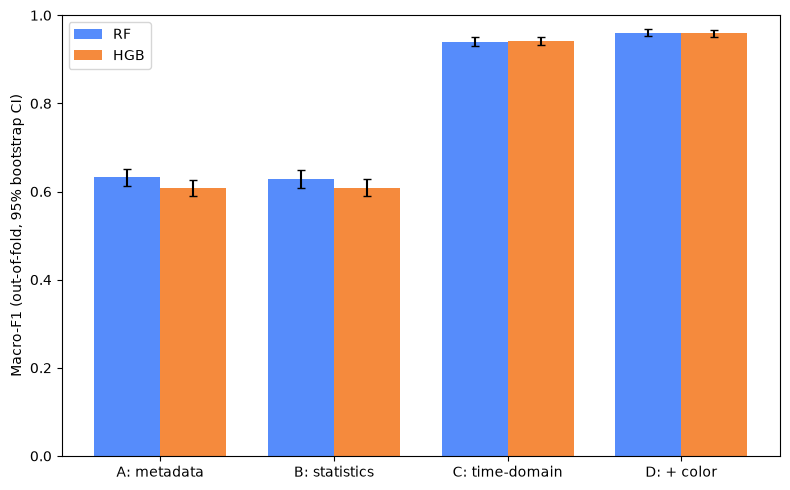

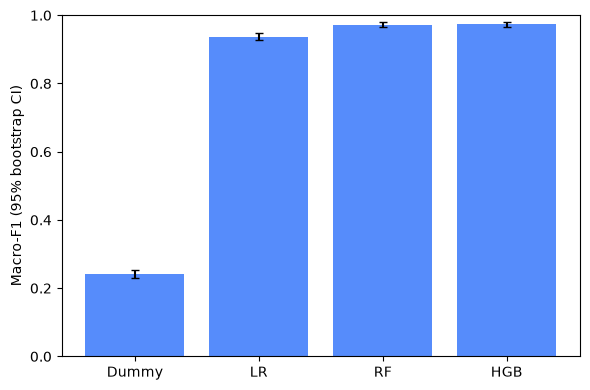

,model,dropped,macro_f1,ci_lo,ci_hi,delta_vs_full
0,RF,magnitude_std,0.9715,0.9643,0.9784,-0.0005
1,RF,amplitude,0.9713,0.9639,0.9785,-0.0007
2,RF,fourier_amp,0.9706,0.9632,0.9776,-0.0014
3,HGB,magnitude_std,0.9729,0.9660,0.9793,-0.0002
4,HGB,amplitude,0.9730,0.9662,0.9796,-0.0001
5,HGB,fourier_amp,0.9729,0.9660,0.9793,-0.0002


In [21]:
labels = ["A: metadata", "B: statistics", "C: time-domain", "D: + color"]
abl = metrics_ci.loc[metrics_ci["feature_set"].isin(ABLATION)]

fig, ax = plt.subplots(figsize=(8, 5))
width = 0.38
for k, name in enumerate(["RF", "HGB"]):
    part = abl.loc[abl["model"].eq(name)].set_index("feature_set").loc[ABLATION]
    ax.bar(np.arange(len(ABLATION)) + (k - 0.5) * width, part["macro_f1"], width, label=name,
           yerr=[(part["macro_f1"] - part["macro_f1_lo"]).to_numpy(),
                 (part["macro_f1_hi"] - part["macro_f1"]).to_numpy()], capsize=3)
ax.set_xticks(range(len(ABLATION)), labels)
ax.set(ylabel="Macro-F1 (out-of-fold, 95% bootstrap CI)", ylim=(0, 1))
ax.legend()
fig.tight_layout()
fig.savefig(PLOT_ROOT / "ablation.png", dpi=160, bbox_inches="tight")
plt.show()

order = ["Dummy", "LR", "RF", "HGB"]
comp = metrics_ci.loc[metrics_ci["feature_set"].eq("full") & metrics_ci["model"].isin(order)].set_index("model").loc[order]
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(order, comp["macro_f1"],
       yerr=[(comp["macro_f1"] - comp["macro_f1_lo"]).to_numpy(),
             (comp["macro_f1_hi"] - comp["macro_f1"]).to_numpy()], capsize=3)
ax.set(ylabel="Macro-F1 (95% bootstrap CI)", ylim=(0, 1))
fig.tight_layout()
fig.savefig(PLOT_ROOT / "model_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

base = metrics_ci.set_index(["model", "feature_set"])
redundancy = pd.DataFrame([{
    "model": n, "dropped": v.removeprefix("drop_"),
    "macro_f1": base.loc[(n, v), "macro_f1"],
    "ci_lo": base.loc[(n, v), "macro_f1_lo"], "ci_hi": base.loc[(n, v), "macro_f1_hi"],
    "delta_vs_full": base.loc[(n, v), "macro_f1"] - base.loc[(n, "full"), "macro_f1"],
} for n in ["RF", "HGB"] for v in REDUNDANCY])
redundancy.to_csv(EXTRA_ROOT / "redundancy.csv", index=False)
display(redundancy.round(4))

## Robustness

In [22]:
stars["n_obs_bin"] = pd.qcut(stars["n_epochs"], 3, labels=["low", "medium", "high"])
stars["g_mag_bin"] = pd.qcut(stars["g_mean_magnitude"], 3, labels=["bright", "middle", "faint"])

robust_rows = []
for name in ["RF", "HGB"]:
    for variant in ["full", "C_timedomain", "D_full"]:
        for bin_col in ["n_obs_bin", "g_mag_bin"]:
            for level in stars[bin_col].cat.categories:
                mask = stars[bin_col].eq(level).to_numpy()
                robust_rows.append({"model": name, "feature_set": variant, "bin": bin_col,
                                    "level": level, **bootstrap_metrics(name, variant, mask)})

robustness = pd.DataFrame(robust_rows)
robustness.to_csv(EXTRA_ROOT / "robustness.csv", index=False)
display(robustness.round(4))

,model,feature_set,bin,level,n_stars,accuracy,accuracy_lo,accuracy_hi,balanced_accuracy,balanced_accuracy_lo,balanced_accuracy_hi,macro_f1,macro_f1_lo,macro_f1_hi
0,RF,full,n_obs_bin,low,715,0.9692,0.9562,0.9813,0.9716,0.9595,0.9834,0.9717,0.9596,0.9830
1,RF,full,n_obs_bin,medium,611,0.9764,0.9646,0.9869,0.9748,0.9617,0.9863,0.9743,0.9610,0.9858
2,RF,full,n_obs_bin,high,652,0.9715,0.9580,0.9825,0.9674,0.9521,0.9805,0.9683,0.9531,0.9805
3,RF,full,g_mag_bin,bright,660,0.9770,0.9652,0.9879,0.9625,0.9393,0.9820,0.9613,0.9391,0.9807
4,RF,full,g_mag_bin,middle,659,0.9636,0.9495,0.9775,0.9638,0.9497,0.9780,0.9599,0.9446,0.9752
5,RF,full,g_mag_bin,faint,659,0.9760,0.9651,0.9869,0.9573,0.9283,0.9820,0.9653,0.9426,0.9828
6,RF,C_timedomain,n_obs_bin,low,715,0.9127,0.8927,0.9315,0.9122,0.8912,0.9319,0.9085,0.8870,0.9281
7,RF,C_timedomain,n_obs_bin,medium,611,0.9437,0.9262,0.9604,0.9430,0.9248,0.9603,0.9416,0.9234,0.9592
8,RF,C_timedomain,n_obs_bin,high,652,0.9660,0.9515,0.9788,0.9644,0.9488,0.9780,0.9652,0.9496,0.9784
9,RF,C_timedomain,g_mag_bin,bright,660,0.9558,0.9415,0.9694,0.9633,0.9486,0.9768,0.9414,0.9178,0.9616


## Period Status

In [23]:
status_rows = []
paired_rows = []

STATUSES = ["recovered", "mismatched", "ineligible"]
PERIOD_SETS = ["full", "oracle", "period_free", "color_amp"]

for name in ["RF", "HGB"]:
    for class_name in CLASSES:
        for status in STATUSES:
            part = oof.loc[
                oof["class_name"].eq(class_name)
                & oof["period_status"].eq(status)
            ]

            if part.empty:
                continue

            variants = [
                variant for variant in PERIOD_SETS
                if status != "ineligible" or variant != "oracle"
            ]

            for variant in variants:
                n, recall, low, high = bootstrap(
                    part, f"correct_{name}_{variant}",
                    seed=SEED + 100 * CLASSES.index(class_name)
                    + 10 * STATUSES.index(status) + PERIOD_SETS.index(variant),
                )

                status_rows.append({
                    "model": name, "class_name": class_name,
                    "period_status": status, "feature_set": variant,
                    "n_stars": n, "recall": recall,
                    "ci_lo": low, "ci_hi": high,
                    "small_cell": n < MIN_CELL,
                })

            pairs = [
                ("full", "period_free"),
                ("full", "color_amp"),
            ]

            if status != "ineligible":
                pairs += [
                    ("full", "oracle"),
                    ("oracle", "period_free"),
                ]

            for first, second in pairs:
                n, delta, low, high = bootstrap(
                    part, f"correct_{name}_{first}",
                    f"correct_{name}_{second}",
                    seed=SEED + 100 * CLASSES.index(class_name)
                    + 10 * STATUSES.index(status) + PERIOD_SETS.index(second),
                )

                paired_rows.append({
                    "model": name, "class_name": class_name,
                    "period_status": status,
                    "reference": first, "compared": second,
                    "n_stars": n, "recall_delta": delta,
                    "ci_lo": low, "ci_hi": high,
                    "small_cell": n < MIN_CELL,
                })

status_scores = pd.DataFrame(status_rows)
paired_status = pd.DataFrame(paired_rows)

status_scores.to_csv(EXTRA_ROOT / "status.csv", index=False)
paired_status.to_csv(EXTRA_ROOT / "paired.csv", index=False)

display(
    status_scores.loc[status_scores["period_status"].eq("mismatched")]
    .round(3)
)

display(
    paired_status.loc[paired_status["period_status"].eq("mismatched")]
    .round(3)
)

,model,class_name,period_status,feature_set,n_stars,recall,ci_lo,ci_hi,small_cell
4,RF,RR Lyrae,mismatched,full,86,0.972,0.937,1.000,False
5,RF,RR Lyrae,mismatched,oracle,86,0.970,0.933,0.998,False
6,RF,RR Lyrae,mismatched,period_free,86,0.977,0.942,1.000,False
7,RF,RR Lyrae,mismatched,color_amp,86,0.407,0.308,0.514,False
12,RF,Cepheid,mismatched,full,5,0.800,0.400,1.000,True
13,RF,Cepheid,mismatched,oracle,5,0.800,0.400,1.000,True
14,RF,Cepheid,mismatched,period_free,5,0.800,0.400,1.000,True
15,RF,Cepheid,mismatched,color_amp,5,0.240,0.000,0.640,True
20,RF,Eclipsing Binary,mismatched,full,488,0.980,0.965,0.992,False
21,RF,Eclipsing Binary,mismatched,oracle,488,0.999,0.997,1.000,False


,model,class_name,period_status,reference,compared,n_stars,recall_delta,ci_lo,ci_hi,small_cell
4,RF,RR Lyrae,mismatched,full,period_free,86,0.005,0.000,0.014,False
5,RF,RR Lyrae,mismatched,full,color_amp,86,-0.565,-0.667,-0.451,False
6,RF,RR Lyrae,mismatched,full,oracle,86,-0.002,-0.014,0.009,False
7,RF,RR Lyrae,mismatched,oracle,period_free,86,0.007,0.000,0.016,False
12,RF,Cepheid,mismatched,full,period_free,5,0.000,0.000,0.000,True
13,RF,Cepheid,mismatched,full,color_amp,5,-0.560,-0.960,-0.160,True
14,RF,Cepheid,mismatched,full,oracle,5,0.000,0.000,0.000,True
15,RF,Cepheid,mismatched,oracle,period_free,5,0.000,0.000,0.000,True
20,RF,Eclipsing Binary,mismatched,full,period_free,488,-0.029,-0.045,-0.015,False
21,RF,Eclipsing Binary,mismatched,full,color_amp,488,-0.362,-0.405,-0.318,False


## Feature Importance

In [24]:
importance_folds = pd.DataFrame(importance_rows)

importance = (
    importance_folds.groupby("feature", as_index=False)
    .agg(
        f1_drop=("macro_f1_drop", "mean"),
        f1_std=("macro_f1_drop", "std"),
    )
    .sort_values("f1_drop", ascending=False)
)

feature_groups = {
    col: name for name, cols in GROUPS.items() for col in cols
}

importance["group"] = importance["feature"].map(feature_groups)

importance_folds.to_csv(EXTRA_ROOT / "importance_folds.csv", index=False)
importance.to_csv(EXTRA_ROOT / "importance.csv", index=False)

display(importance.head(15).round(4))

,feature,f1_drop,f1_std,group
10,log_period,0.1565,0.0226,period
14,magnitude_skew,0.1335,0.0169,shape
3,bp_rp_color,0.0814,0.0184,color
18,power,0.0796,0.0079,period
22,stetson_j,0.0077,0.0031,timescale
17,median_error,0.0074,0.0013,brightness_noise
20,sf_ratio,0.0072,0.0061,timescale
21,sf_short,0.0036,0.0039,timescale
11,magnitude_kurt,0.0024,0.0015,shape
1,amplitude_ratio,0.0022,0.0028,brightness_noise


In [25]:
family_importance = (
    pd.DataFrame(family_rows).groupby("family")["macro_f1_drop"]
    .agg(f1_drop="mean", f1_std="std").sort_values("f1_drop", ascending=False)
)
family_importance.to_csv(EXTRA_ROOT / "importance_family.csv")
display(family_importance.round(4))

,f1_drop,f1_std
family,,
period,0.2543,0.0247
timescale,0.1818,0.0405
shape,0.1633,0.0185
color,0.0802,0.0190
brightness_noise,0.0214,0.0066


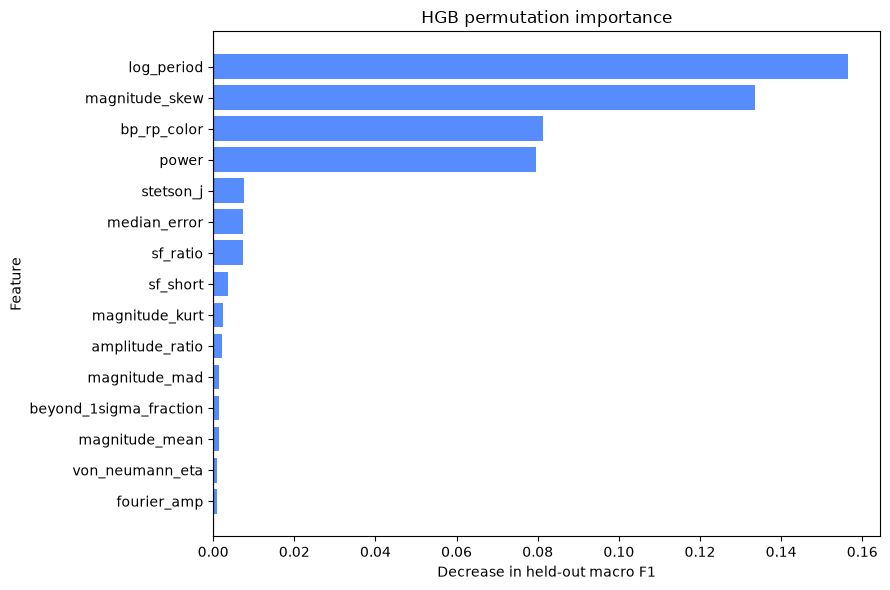

In [26]:
top = importance.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(top["feature"], top["f1_drop"])
ax.axvline(0, color="black", linewidth=0.8)
ax.set(
    xlabel="Decrease in held-out macro F1",
    ylabel="Feature",
    title="HGB permutation importance",
)

fig.tight_layout()
fig.savefig(PLOT_ROOT / "importance.png", dpi=160, bbox_inches="tight")
plt.show()

## Confusion Matrix

,RR Lyrae,Cepheid,Eclipsing Binary,Long-Period Variable
RR Lyrae,457,8,13,0
Cepheid,11,482,1,6
Eclipsing Binary,5,4,491,0
Long-Period Variable,1,3,1,495


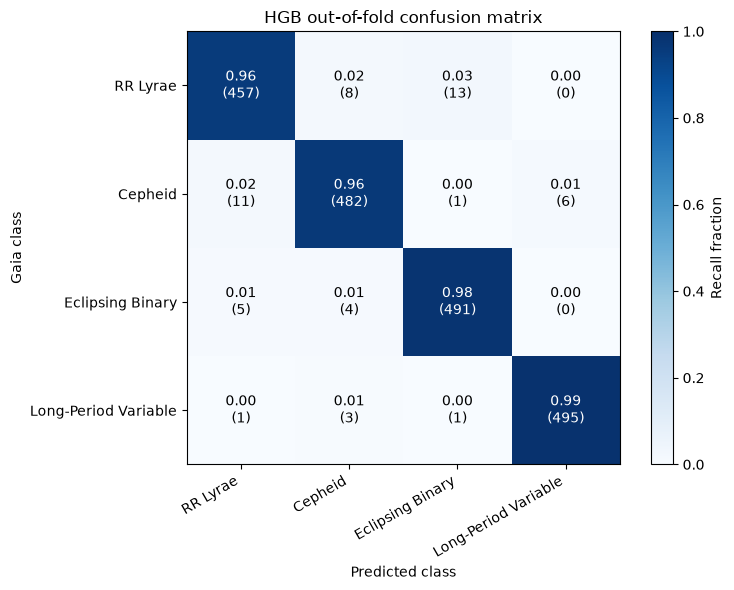

In [27]:
first = oof.loc[oof["repeat"].eq(1)]

cm = confusion_matrix(
    first["class_name"], first["pred_HGB_full"], labels=CLASSES
)

rates = cm / cm.sum(axis=1, keepdims=True)

display(pd.DataFrame(cm, index=CLASSES, columns=CLASSES))

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(rates, vmin=0, vmax=1, cmap="Blues")

ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=30, ha="right")
ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set(
    xlabel="Predicted class",
    ylabel="Gaia class",
    title="HGB out-of-fold confusion matrix",
)

for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(
            j, i, f"{rates[i, j]:.2f}\n({cm[i, j]})",
            ha="center", va="center",
            color="white" if rates[i, j] > 0.5 else "black",
        )

fig.colorbar(image, ax=ax, label="Recall fraction")
fig.tight_layout()
fig.savefig(PLOT_ROOT / "confusion.png", dpi=160, bbox_inches="tight")
plt.show()

In [28]:
p, r, f, s = precision_recall_fscore_support(
    oof["class_name"], oof["pred_HGB_full"], labels=CLASSES, zero_division=0
)
per_class = pd.DataFrame({
    "class_name": CLASSES, "precision": p, "recall": r, "f1": f, "n_per_repeat": s // REPEATS,
})
per_class.to_csv(EXTRA_ROOT / "per_class.csv", index=False)
display(per_class.round(4))

,class_name,precision,recall,f1,n_per_repeat
0,RR Lyrae,0.9626,0.9594,0.9610,478
1,Cepheid,0.9709,0.9616,0.9662,500
2,Eclipsing Binary,0.9715,0.9812,0.9763,500
3,Long-Period Variable,0.9876,0.9904,0.9890,500


## Final Model

In [29]:
final_model = make_model("HGB", "full")
final_model.fit(stars[BASE_FEATURES], y)

joblib.dump(final_model, MODEL_FILE)

metadata = {
    "model": "HGB",
    "sources": len(stars),
    "folds": FOLDS,
    "repeats": REPEATS,
    "classes": CLASSES,
    "features": BASE_FEATURES,
    "groups": GROUPS,
    "sky_group": "Gaia feature-engineering sky cells",
    "period_reference": "Gaia DR3 published period",
    "recovery_rule": "phase drift <= 0.25 cycles",
}

with (EXTRA_ROOT / "metadata.json").open("w") as file:
    json.dump(metadata, file, indent=2)

print("Model:", MODEL_FILE)
print("CV scores:", CV_FILE)
print("CV ranking:", RANK_FILE)
print("OOF predictions:", PRED_FILE)
print("Results:", EXTRA_ROOT)
print("Figures:", PLOT_ROOT)

Model: /Users/Sumaitat/Documents/Coding/gaia-varstars/models/model.joblib
CV scores: /Users/Sumaitat/Documents/Coding/gaia-varstars/models/cv.csv
CV ranking: /Users/Sumaitat/Documents/Coding/gaia-varstars/models/rank.csv
OOF predictions: /Users/Sumaitat/Documents/Coding/gaia-varstars/models/pred.csv
Results: /Users/Sumaitat/Documents/Coding/gaia-varstars/models/gaia_classification
Figures: /Users/Sumaitat/Documents/Coding/gaia-varstars/reports/figures/gaia_classification
